Loaded Fig.3 uncertainty files:
  unconstrained_variance shape: (144, 192)
  constrained_variance shape:   (144, 192)
  filtered_variance shape:      (144, 192)

Reference N96 grid loaded:
  file: /gws/ssde/j25a/acure/phase3/netcdf_output/CCN_components/monthly_processed/jan/ACURE_P3_CCN_0.2pc_PD_220.nc
  latitudes shape: (144,)
  sorted_longitudes shape: (192,)
  latitude range: -89.375 89.375
  longitude range: -179.0625 179.0625

Reconstructed valid grid after ERFaci_var >= 0.5 mask:
  lat_valid shape: (110,)
  lon_valid shape: (192,)
  lat_valid range: -59.375 79.375
  lon_valid range: -179.0625 179.0625

Loaded cluster file:
  file: /home/users/jianxing/ERFaci_optimal_constraint_clusters.nc
  variable: Cluster
  cluster_raw shape: (110, 192)
  target cluster ids: [1.0, 5.0, 7.0]

Cluster valid-grid check:
  cluster_valid shape: (110, 192)
  expected shape: (110, 192)

latitude coordinate mapping:
  n values: 110
  max nearest-coordinate difference: 0.0

longitude coordinate mappin

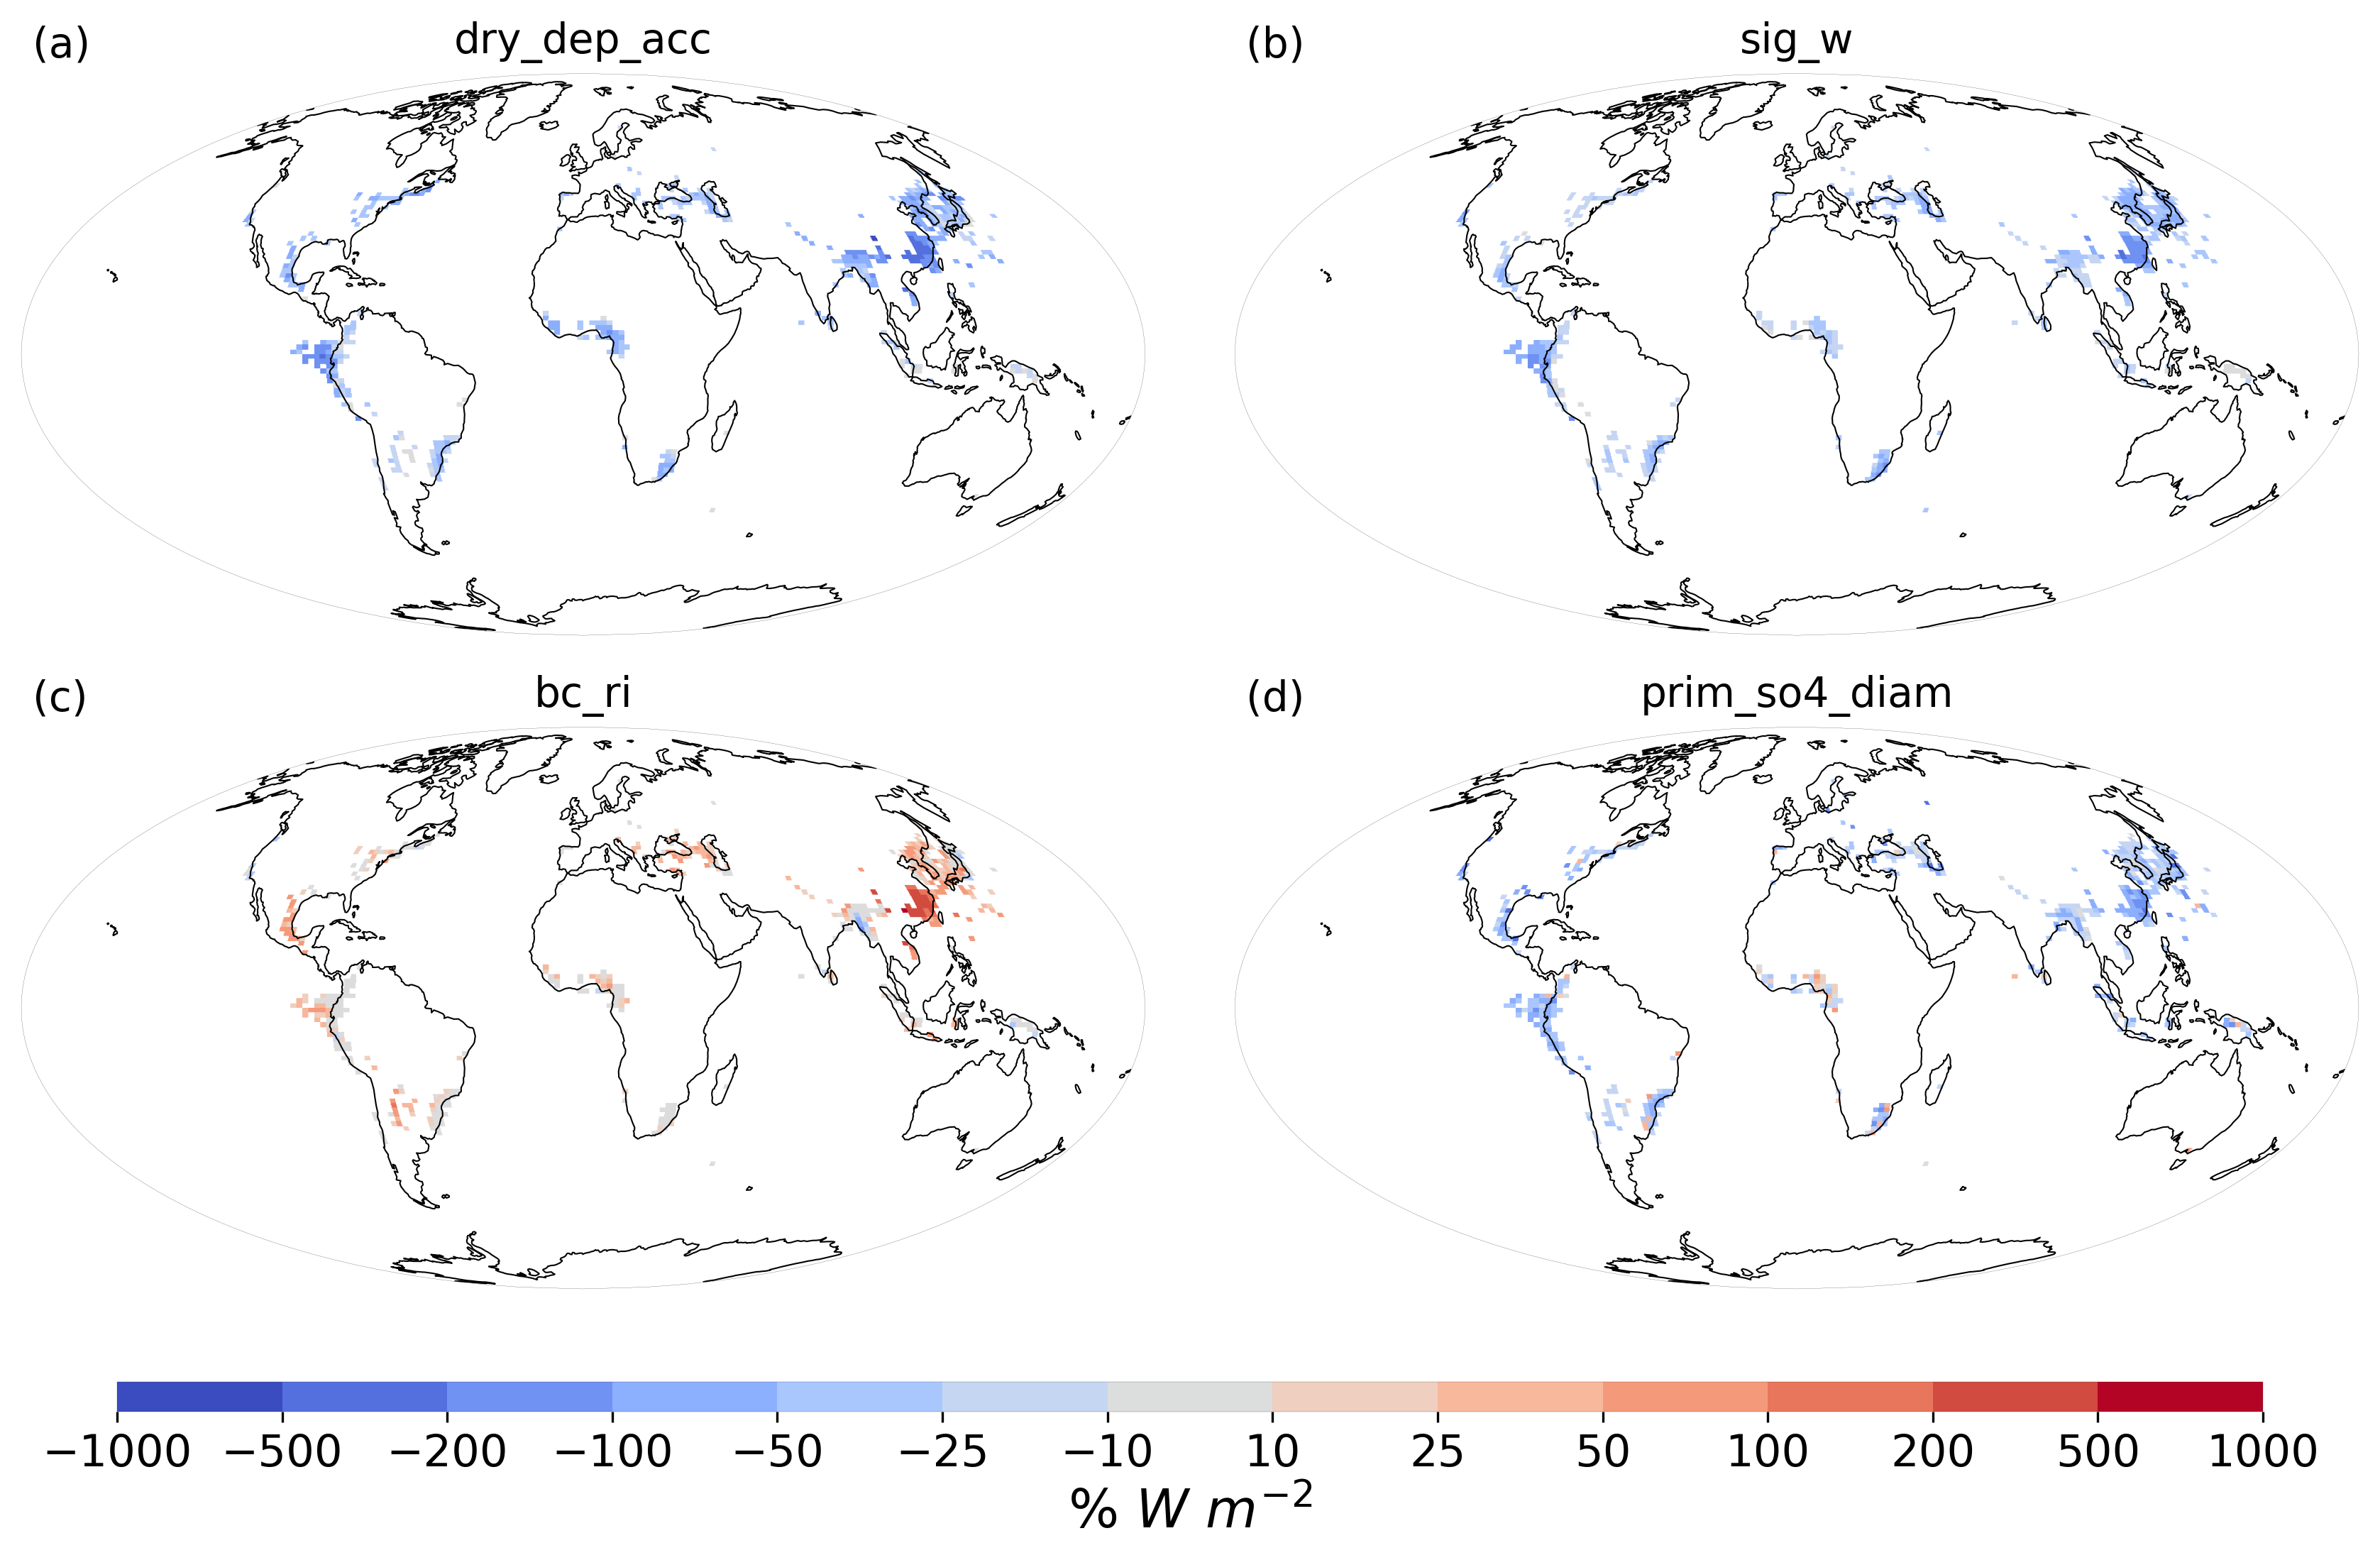

Final plotting mask for: Cluster 2
  actual cluster id: 5.0
  var_min: 3 W m^-2
  total gridboxes: 27648
  target cluster gridboxes before var_min mask: 988
  visible gridboxes after cluster + uncertainty mask: 893

Plotting cluster figure
  parameters:
    18: dry_dep_acc
    25: bc_ri
    28: bparam
    06: prim_so4_diam



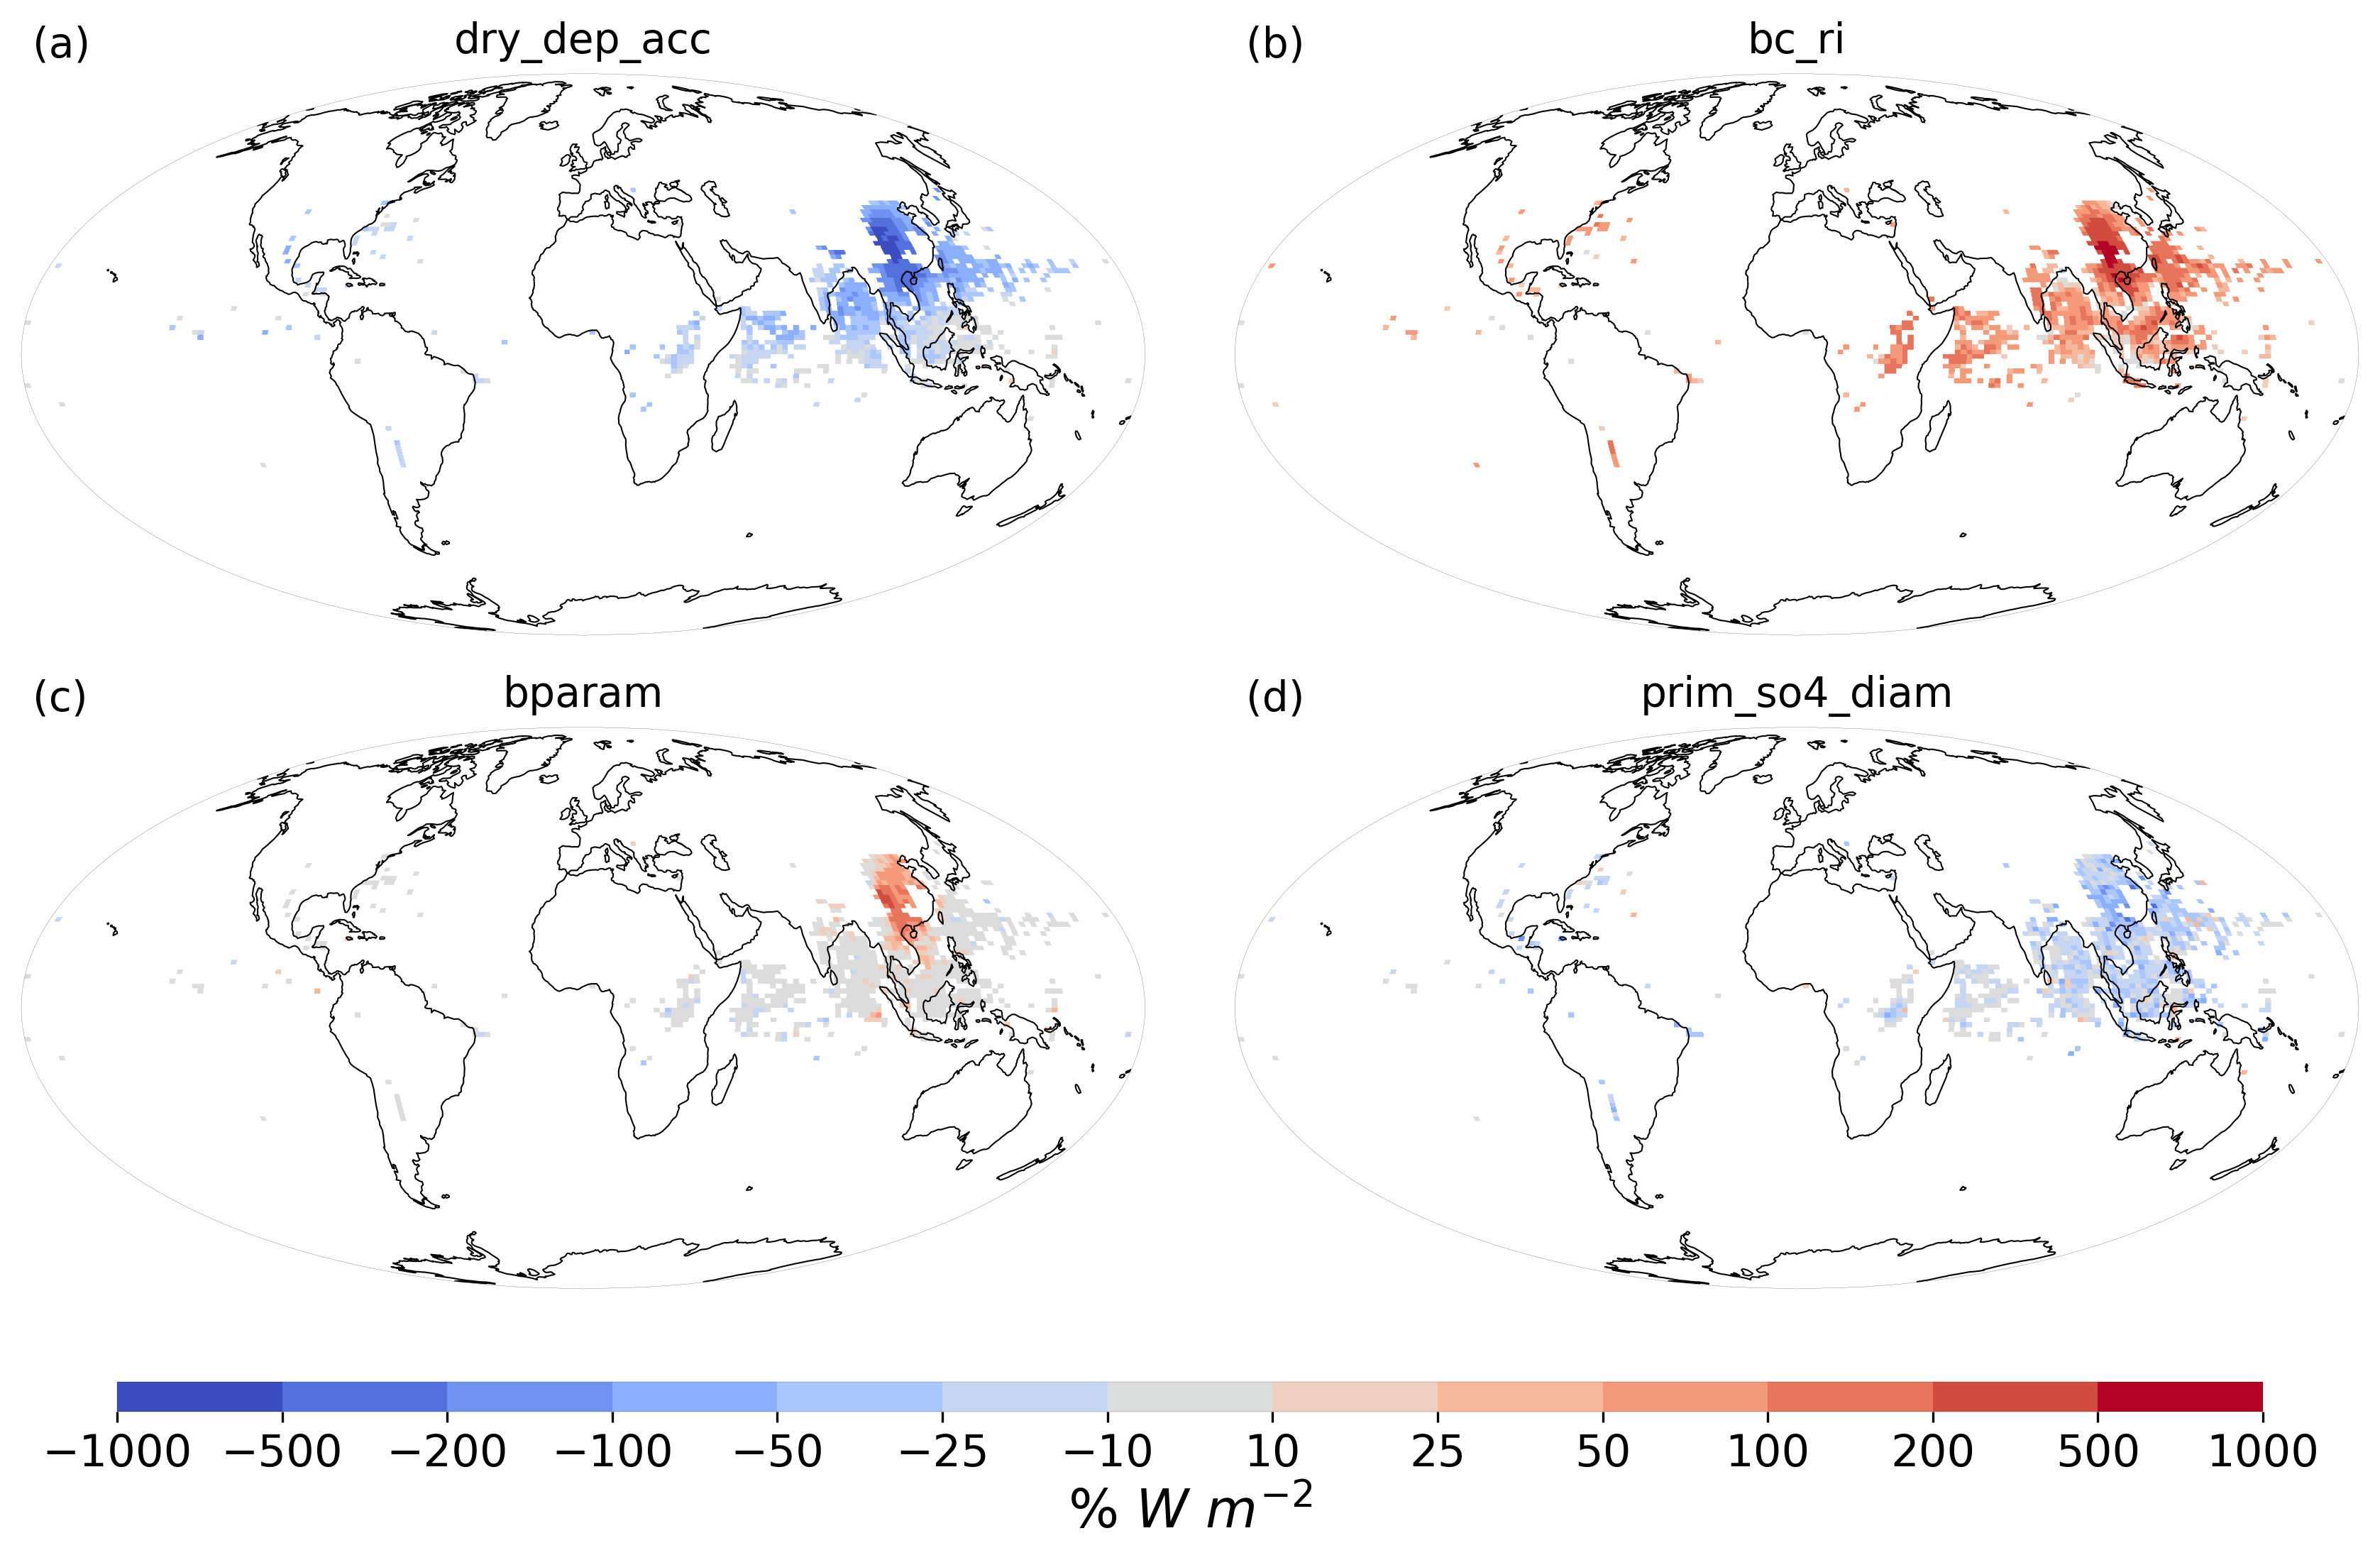

Final plotting mask for: Cluster 3
  actual cluster id: 7.0
  var_min: 3 W m^-2
  total gridboxes: 27648
  target cluster gridboxes before var_min mask: 660
  visible gridboxes after cluster + uncertainty mask: 607

Plotting cluster figure
  parameters:
    35: m_ci
    34: ai
    33: dbsdtbs_turb_0
    15: dms



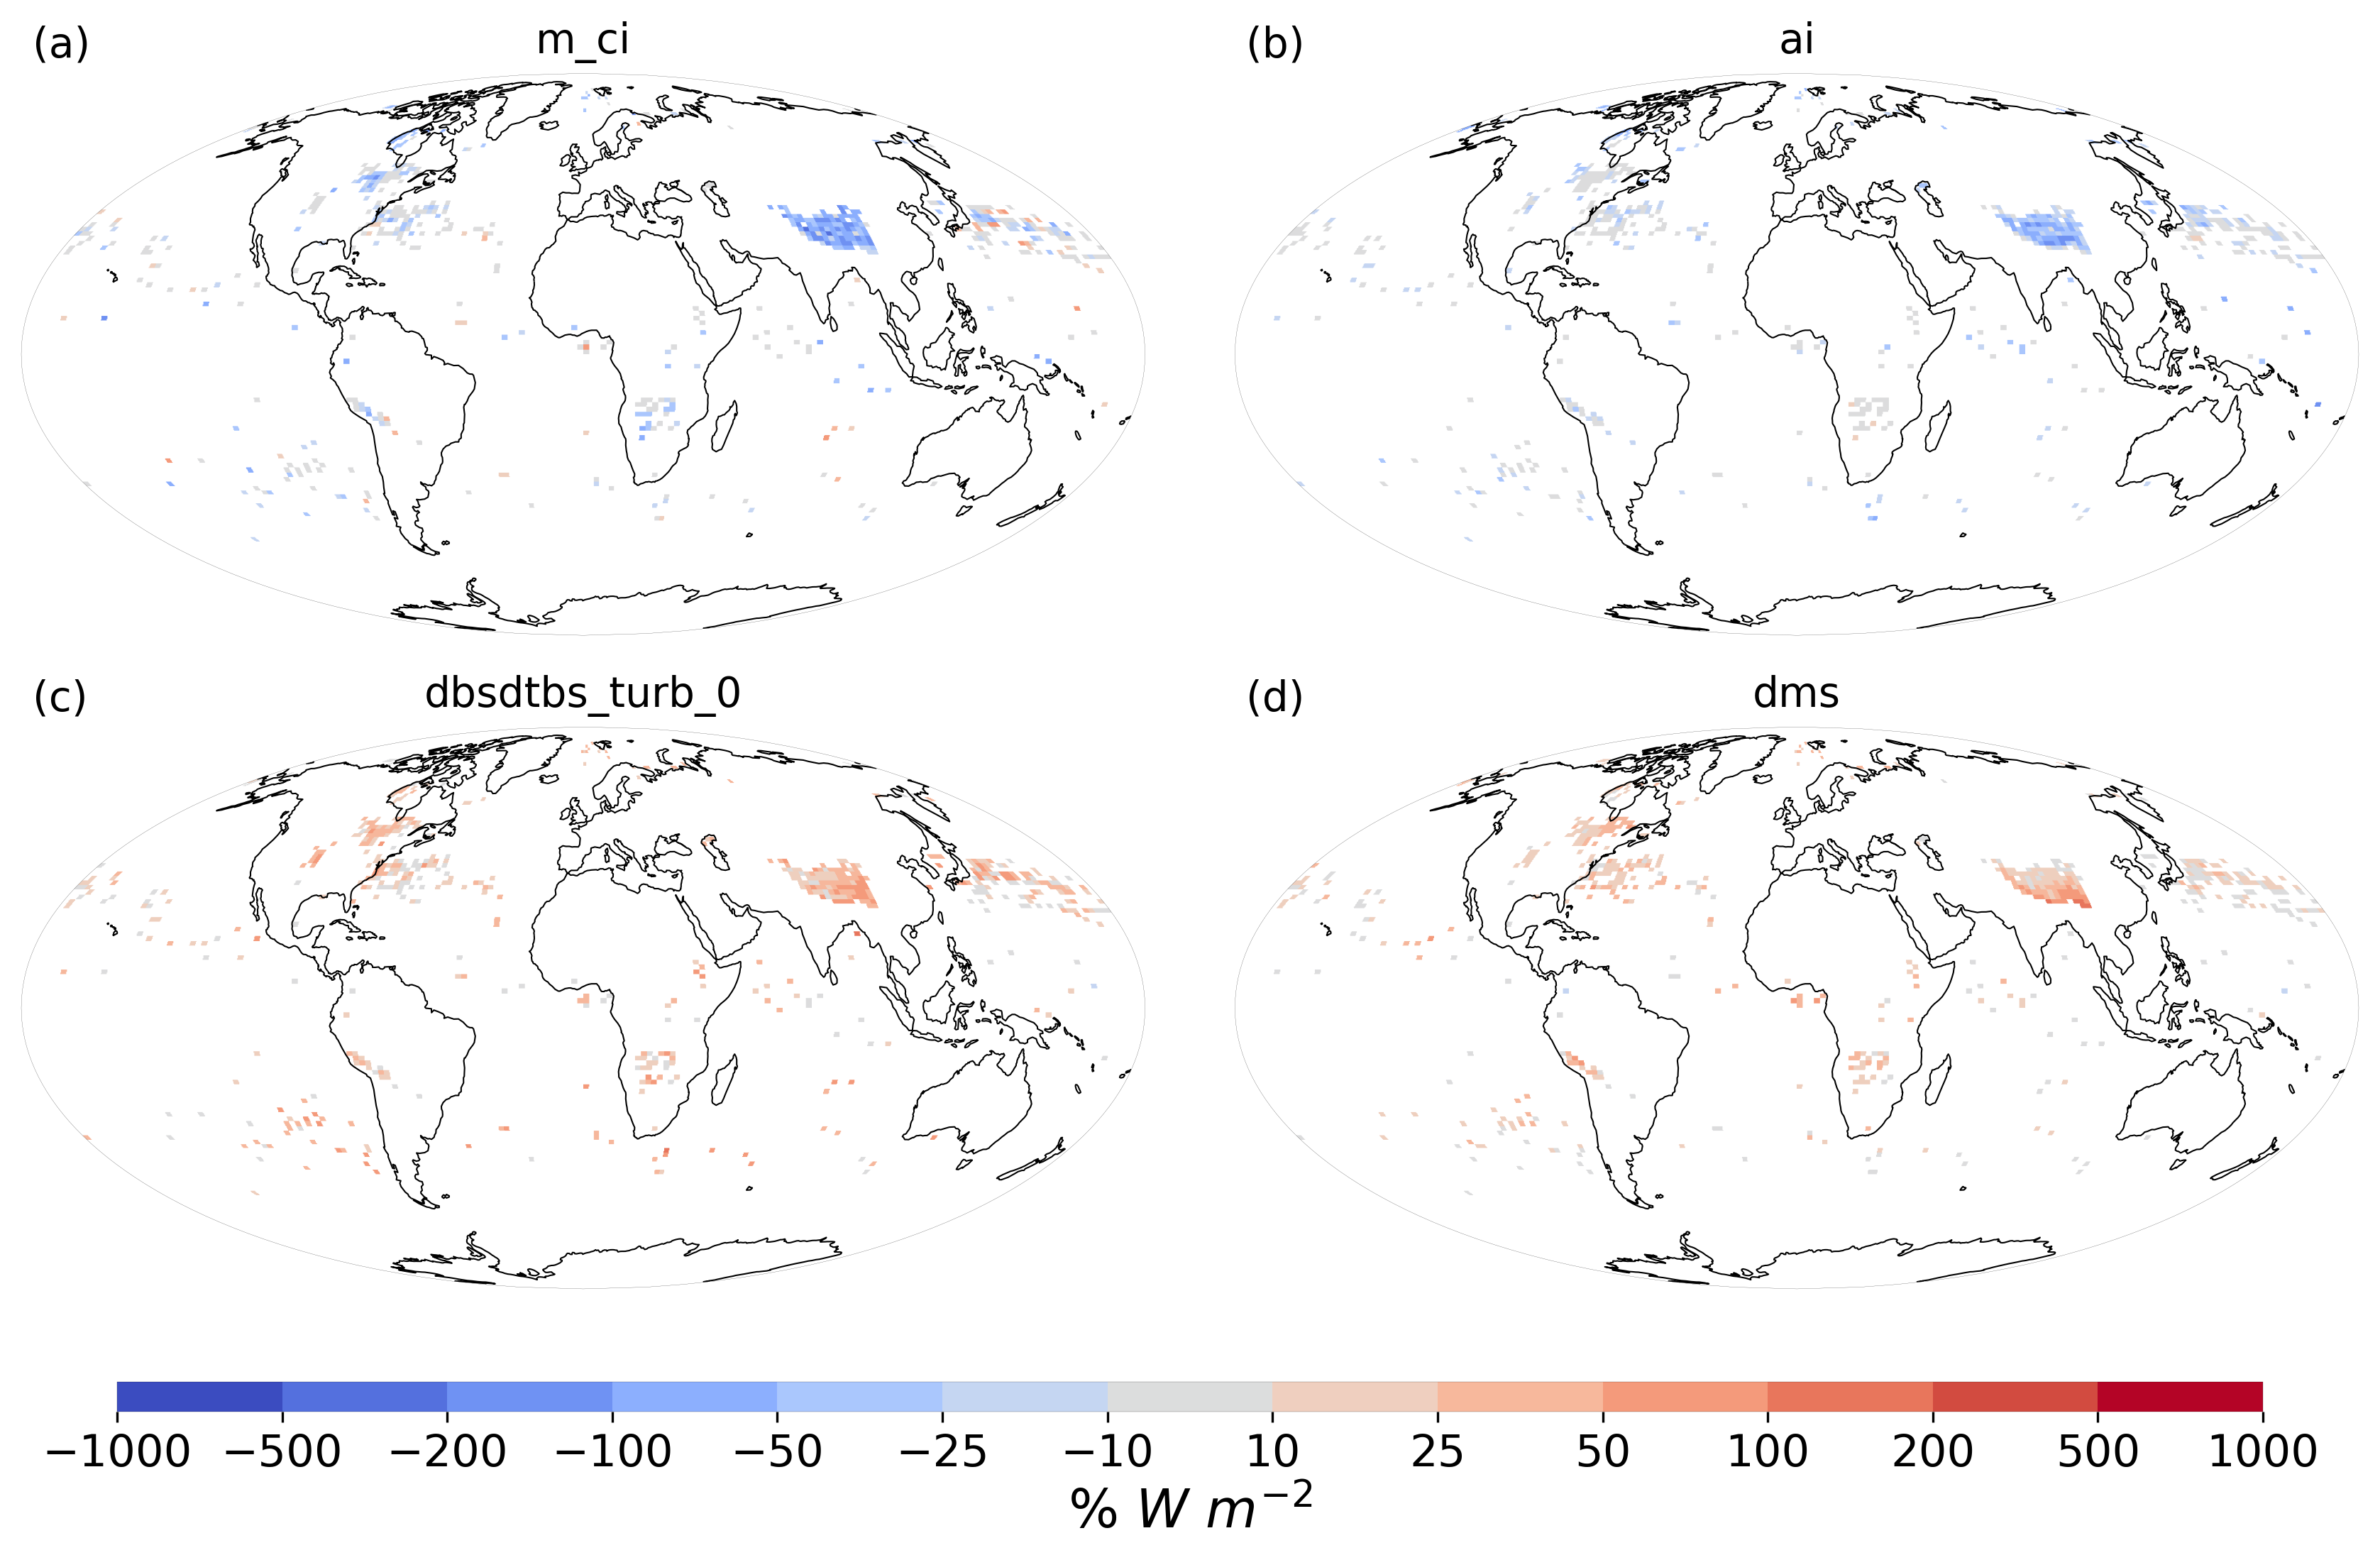

Done. No files were saved. Figures were displayed directly in the notebook.


In [1]:
# ============================================================
# Fig.3 style map for ERFaci parameter contributions
# Three separate figures:
#   1. Actual cluster 1, displayed as Cluster 1
#   2. Actual cluster 5, displayed as Cluster 2
#   3. Actual cluster 7, displayed as Cluster 3
#
# Notebook version:
#   - Do not save any files
#   - Display figures directly using plt.show()
#   - Print key diagnostic information
#
# Important update:
#   The cluster file was generated after removing ERFaci_var < 0.5,
#   and its longitudes were already converted to sorted_longitudes (-180 to 180).
#
# Therefore:
#   1. Use the actual N96 latitude and longitude coordinates.
#   2. Convert longitudes to the -180 to 180 range and sort them.
#   3. Read ERFaci variance and reproduce the ERFaci_var < 0.5 drop.
#   4. Obtain lat_valid and lon_valid.
#   5. Map clusters 1/5/7 back to the full 144 x 192 sorted-longitude grid.
#   6. Continue using reverse_lat_lon_shift_w_o_bounds() for Fig.3 contribution arrays.
#   7. Flip only latitude for cluster masks; do not shift longitude again.
#
# Path update:
#   /gws/nopw/j04/acure/  ->  /gws/ssde/j25a/acure/
# ============================================================


# ============================================================
# 0. Import libraries
# ============================================================

import os
import string
from math import *

import numpy as np
import xarray as xr

import iris
import iris.plot as iplt

import matplotlib
import matplotlib as mp
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import MaxNLocator
import matplotlib.lines as mlines
from matplotlib.patches import Polygon
from matplotlib.backends.backend_pdf import PdfPages

import cartopy.crs as ccrs
import cartopy.feature as cfeat

from netCDF4 import Dataset as nd

import pylab
import pylab as pl

from collections import Counter
import numpy.ma as ma


# ============================================================
# 1. Paths
# ============================================================

GAM_path = "/gws/ssde/j25a/acure/lregayre/GAM_values/gridbox/ann/ERFaci/"

variance_path = (
    "/gws/ssde/j25a/acure/lregayre/data_post_emulation/"
    "gridbox/ann/ERFaci/CIs/"
)

cluster_path = "/home/users/jianxing/ERFaci_optimal_constraint_clusters.nc"

# Reference file providing the original N96 latitude and longitude coordinates
ref_grid_file = (
    "/gws/ssde/j25a/acure/phase3/netcdf_output/"
    "CCN_components/monthly_processed/jan/"
    "ACURE_P3_CCN_0.2pc_PD_220.nc"
)

# This file supplies the same xarray template used during cluster generation.
erf_mask_template_file = (
    "/home/users/jianxing/lea/"
    "ERF_aci_variances_filtered_prim_so4_optimally_constrained.nc"
)

# ERFaci variance file used in the drop step of the original cluster-generation procedure
erf_variance_for_cluster_mask_file = (
    "/gws/ssde/j25a/acure/lregayre/data_post_emulation/"
    "gridbox/ann/ERFaci/variances/"
    "optimally_constrained_ERFaci_ann_5k_member.dat"
)

cluster_ids = [1.0, 5.0, 7.0]

# Cluster labels for display:
#   Actual cluster 1 is displayed as Cluster 1.
#   Actual cluster 5 is displayed as Cluster 2.
#   Actual cluster 7 is displayed as Cluster 3.
cluster_display_label_dict = {
    1.0: "Cluster 1",
    5.0: "Cluster 2",
    7.0: "Cluster 3",
}


# ============================================================
# 2. Read ERFaci uncertainty files for Fig.3 weighting
# ============================================================

unconstrained_variance = np.loadtxt(
    variance_path + "unconstrained_ERFaci_ann_1million_member.dat"
)

constrained_variance = np.loadtxt(
    variance_path + "optimally_constrained_ERFaci_ann_5k_member.dat"
)

filtered_variance = np.loadtxt(
    variance_path + "prim_so4_diam_filtered_ERFaci_ann_898610_member.dat"
)

print("Loaded Fig.3 uncertainty files:")
print("  unconstrained_variance shape:", unconstrained_variance.shape)
print("  constrained_variance shape:  ", constrained_variance.shape)
print("  filtered_variance shape:     ", filtered_variance.shape)
print("")

nlat = 144
nlon = 192

if unconstrained_variance.shape != (nlat, nlon):
    raise ValueError(
        f"unconstrained_variance shape is {unconstrained_variance.shape}, "
        f"expected {(nlat, nlon)}"
    )

if constrained_variance.shape != (nlat, nlon):
    raise ValueError(
        f"constrained_variance shape is {constrained_variance.shape}, "
        f"expected {(nlat, nlon)}"
    )

if filtered_variance.shape != (nlat, nlon):
    raise ValueError(
        f"filtered_variance shape is {filtered_variance.shape}, "
        f"expected {(nlat, nlon)}"
    )


# ============================================================
# 3. Function from original Fig.3 program
# ============================================================

def reverse_lat_lon_shift_w_o_bounds(var_array):
    """
    Original Fig_3_A2_and_A3.py function.

    Apply the following operations to the original Fig.3 144 x 192 array:
      1. flip latitude
      2. shift longitude by half domain

    Note:
      This function still applies to the Fig.3 parameter contribution and uncertainty arrays.
      It is not used for cluster masks, whose longitudes are already sorted.
    """
    nlat_local = var_array.shape[0]
    nlon_local = var_array.shape[1]
    half_lon = int(nlon_local / 2)

    lat_flip_array = np.zeros((nlat_local, nlon_local))

    for ilon in np.arange(nlon_local):
        lat_flip_array[:, ilon] = np.flip(var_array[:, ilon])

    lon_shift_array = np.zeros((nlat_local, nlon_local))
    lon_shift_array[:, 0:half_lon] = lat_flip_array[:, half_lon:]
    lon_shift_array[:, half_lon:] = lat_flip_array[:, 0:half_lon]

    return lon_shift_array


# ============================================================
# 4. Read cluster file and rebuild target cluster masks
#    using the same valid lat/lon logic used when clusters were created
# ============================================================

# ------------------------------------------------------------
# 4.1 Reference N96 latitude / longitude from real model output
# ------------------------------------------------------------

ref_ds = xr.load_dataset(ref_grid_file)

latitudes = ref_ds.latitude.values
longitudes = ref_ds.longitude.values.copy()

# Convert 0-360 longitude to -180 to 180, then sort,
# exactly following your previous processing logic.
longitudes_fixed = np.where(longitudes > 180, longitudes - 360, longitudes)
sorted_longitudes = np.array(sorted(longitudes_fixed))

print("Reference N96 grid loaded:")
print("  file:", ref_grid_file)
print("  latitudes shape:", latitudes.shape)
print("  sorted_longitudes shape:", sorted_longitudes.shape)
print("  latitude range:", np.nanmin(latitudes), np.nanmax(latitudes))
print("  longitude range:", np.nanmin(sorted_longitudes), np.nanmax(sorted_longitudes))
print("")

if len(latitudes) != nlat or len(sorted_longitudes) != nlon:
    raise ValueError(
        f"Reference grid is ({len(latitudes)}, {len(sorted_longitudes)}), "
        f"expected ({nlat}, {nlon})."
    )


# ------------------------------------------------------------
# 4.2 Reproduce the ERFaci variance mask used before clustering
# ------------------------------------------------------------

ds_mask_template = xr.open_dataset(erf_mask_template_file)

# Assign the real N96 coordinates, exactly as in your cluster-generation logic.
# Longitude uses sorted_longitudes, so subsequent cluster masks are already in -180 to 180 order.
ds_2 = ds_mask_template.assign_coords(
    longitude=sorted_longitudes,
    latitude=latitudes
)

ERF_var_for_cluster_mask = np.loadtxt(erf_variance_for_cluster_mask_file)

if ERF_var_for_cluster_mask.shape != (nlat, nlon):
    raise ValueError(
        f"ERF_var_for_cluster_mask shape is {ERF_var_for_cluster_mask.shape}, "
        f"expected ({nlat}, {nlon}). "
        "Please check the ERFaci variance file."
    )

ds_2 = ds_2.assign(
    ERFaci_var=(["latitude", "longitude"], ERF_var_for_cluster_mask)
)

# This reproduces the valid grid used to create your cluster file.
mask_erf_small = ds_2.ERFaci_var < 0.5
ds_2_excluded = ds_2.where(~mask_erf_small, drop=True)

lat_valid = ds_2_excluded.latitude.values
lon_valid = ds_2_excluded.longitude.values

print("Reconstructed valid grid after ERFaci_var >= 0.5 mask:")
print("  lat_valid shape:", lat_valid.shape)
print("  lon_valid shape:", lon_valid.shape)
print("  lat_valid range:", np.nanmin(lat_valid), np.nanmax(lat_valid))
print("  lon_valid range:", np.nanmin(lon_valid), np.nanmax(lon_valid))
print("")


# ------------------------------------------------------------
# 4.3 Read cluster file
# ------------------------------------------------------------

cluster_ds = xr.open_dataset(cluster_path)

if "Cluster" in cluster_ds.data_vars:
    cluster_var_name = "Cluster"
else:
    cluster_var_name = list(cluster_ds.data_vars)[0]

cluster_raw = cluster_ds[cluster_var_name].values
cluster_raw = np.squeeze(cluster_raw)

print("Loaded cluster file:")
print("  file:", cluster_path)
print("  variable:", cluster_var_name)
print("  cluster_raw shape:", cluster_raw.shape)
print("  target cluster ids:", cluster_ids)
print("")


# ------------------------------------------------------------
# 4.4 Make sure cluster shape matches reconstructed valid grid
# ------------------------------------------------------------

expected_shape = (len(lat_valid), len(lon_valid))

if cluster_raw.shape == expected_shape:
    cluster_valid = cluster_raw

elif cluster_raw.T.shape == expected_shape:
    print("Cluster array appears transposed. Transposing cluster_raw.")
    cluster_valid = cluster_raw.T

else:
    raise ValueError(
        "Cluster shape does not match reconstructed valid grid.\n"
        f"  cluster_raw shape: {cluster_raw.shape}\n"
        f"  expected shape:    {expected_shape}\n"
        "Please check whether the cluster file was created using the same "
        "ERFaci_var < 0.5 drop logic."
    )

print("Cluster valid-grid check:")
print("  cluster_valid shape:", cluster_valid.shape)
print("  expected shape:", expected_shape)
print("")


# ------------------------------------------------------------
# 4.5 Map valid-grid cluster values back to full 144 x 192
#     sorted-longitude grid
#
#     Important update:
#       Build a separate mask for each cluster:
#         cluster_mask_dict[1.0]
#         cluster_mask_dict[5.0]
#         cluster_mask_dict[7.0]
# ------------------------------------------------------------

def nearest_index_array(full_values, subset_values, name, tolerance=1e-4):
    """
    Map subset coordinate values back to their nearest index
    in the full coordinate array.
    """
    full_values = np.asarray(full_values, dtype=float)
    subset_values = np.asarray(subset_values, dtype=float)

    indices = []
    max_diff = 0.0

    for v in subset_values:
        idx = int(np.argmin(np.abs(full_values - v)))
        diff = float(np.abs(full_values[idx] - v))
        max_diff = max(max_diff, diff)

        if diff > tolerance:
            print(
                f"Warning: {name} coordinate match difference is large: "
                f"value={v}, nearest={full_values[idx]}, diff={diff}"
            )

        indices.append(idx)

    print(f"{name} coordinate mapping:")
    print("  n values:", len(indices))
    print("  max nearest-coordinate difference:", max_diff)
    print("")

    return np.asarray(indices, dtype=int)


lat_indices = nearest_index_array(
    full_values=latitudes,
    subset_values=lat_valid,
    name="latitude",
    tolerance=1e-4
)

lon_indices = nearest_index_array(
    full_values=sorted_longitudes,
    subset_values=lon_valid,
    name="longitude",
    tolerance=1e-4
)

finite_cluster_values = cluster_valid[np.isfinite(cluster_valid)]

print("Unique cluster values in valid grid:")
print(" ", np.unique(finite_cluster_values))
print("")

cluster_mask_dict = {}

for icluster in cluster_ids:

    cluster_target_valid = cluster_valid == icluster

    # This cluster_mask is already arranged with:
    #   latitude in the original latitudes order
    #   longitude in sorted_longitudes (-180 to 180) order
    # Only latitude needs flipping later; no further longitude shift is needed.
    cluster_mask = np.zeros((nlat, nlon), dtype=bool)
    cluster_mask[np.ix_(lat_indices, lon_indices)] = cluster_target_valid

    cluster_mask_dict[icluster] = cluster_mask

    print(f"{cluster_display_label_dict[icluster]} mask rebuilt on full 144 x 192 sorted-longitude grid:")
    print("  actual cluster id:", icluster)
    print("  cluster_mask shape:", cluster_mask.shape)
    print("  cluster gridboxes:", int(np.sum(cluster_mask)))
    print("")


# ============================================================
# 5. Parameter names for plotting - 37
# ============================================================

par_index_for_plotting_55 = (
    0, 1, 2,
    20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
    34, 35, 36, 37, 38, 39, 40, 41,
    43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54
)

npar = len(par_index_for_plotting_55)

parameter_names_55 = [
    "bl_nuc",
    "ait_width",
    "cloud_ph",
    "carb_ff_ems_eur",
    "carb_ff_ems_nam",
    "carb_ff_ems_chi",
    "carb_ff_ems_asi",
    "carb_ff_ems_mar",
    "carb_ff_ems_r",
    "carb_bb_ems_sam",
    "carb_bb_ems_naf",
    "carb_bb_ems_saf",
    "carb_bb_ems_bnh",
    "carb_bb_ems_rnh",
    "carb_bb_ems_rsh",
    "carb_res_ems_chi",
    "carb_res_ems_asi",
    "carb_res_ems_afr",
    "carb_res_ems_lat",
    "carb_res_ems_r",
    "carb_ff_diam",
    "carb_bb_diam",
    "carb_res_diam",
    "prim_so4_diam",
    "sea_spray",
    "anth_so2_chi",
    "anth_so2_asi",
    "anth_so2_eur",
    "anth_so2_nam",
    "anth_so2_r",
    "volc_so2",
    "bvoc_soa",
    "dms",
    "prim_moc",
    "dry_dep_ait",
    "dry_dep_acc",
    "dry_dep_so2",
    "kappa_oc",
    "sig_w",
    "rain_frac",
    "cloud_ice_thresh",
    "conv_plume_scav",
    "scav_diam",
    "bc_ri",
    "oxidants_oh",
    "oxidants_o3",
    "bparam",
    "two_d_fsd_factor",
    "c_r_correl",
    "autoconv_exp_lwp",
    "autoconv_exp_nd",
    "dbsdtbs_turb_0",
    "ai",
    "m_ci",
    "a_ent_1_rp",
]

parameter_names_37 = []

for ipar in par_index_for_plotting_55:
    parameter_names_37.append(parameter_names_55[ipar])

# Match original plot labels
parameter_names_37[7] = "sea_salt"
parameter_names_37[2] = "cloud_drop_acidity"

print("Parameter setup:")
print("  npar:", npar)
print("  parameter_names_37:")
for i, name in enumerate(parameter_names_37):
    print(f"    {i:02d}: {name}")
print("")


# ============================================================
# 6. Read GAM proportions of variance for lat folders
# ============================================================

parameter_variances_unconstrained_array = np.zeros((npar, nlat, nlon))
parameter_variances_constrained_array = np.zeros((npar, nlat, nlon))
parameter_variances_filtered_array = np.zeros((npar, nlat, nlon))

gradient_sign_unconstrained_array = np.zeros((npar, nlat, nlon))
gradient_sign_constrained_array = np.zeros((npar, nlat, nlon))
gradient_sign_filtered_array = np.zeros((npar, nlat, nlon))

print("Reading GAM variance and gradient-sign files...")

for ilat in np.arange(nlat):
    print("  reading ilat:", ilat)

    for ilon in np.arange(nlon):

        parameter_variances_unconstrained_array[:, ilat, ilon] = np.loadtxt(
            GAM_path
            + "/lat" + str(ilat)
            + "/GAM_variances_from_emulated_mean_ERF_aci_ann_unconstrained_1000000_at_ilat_"
            + str(ilat)
            + "_ilon_"
            + str(ilon)
            + ".dat"
        )

        parameter_variances_constrained_array[:, ilat, ilon] = np.loadtxt(
            GAM_path
            + "/lat" + str(ilat)
            + "/GAM_variances_from_emulated_mean_ERF_aci_ann_constrained_5000_at_ilat_"
            + str(ilat)
            + "_ilon_"
            + str(ilon)
            + ".dat"
        )

        parameter_variances_filtered_array[:, ilat, ilon] = np.loadtxt(
            GAM_path
            + "/lat" + str(ilat)
            + "/GAM_variances_from_emulated_mean_ERF_aci_ann_filtered_prim_so4_diam_898610_at_ilat_"
            + str(ilat)
            + "_ilon_"
            + str(ilon)
            + ".dat"
        )

        gradient_sign_unconstrained_array[:, ilat, ilon] = np.loadtxt(
            GAM_path
            + "/lat" + str(ilat)
            + "/GAM_gradient_signs_from_emulated_mean_ERF_aci_ann_unconstrained_1000000_at_ilat_"
            + str(ilat)
            + "_ilon_"
            + str(ilon)
            + ".dat"
        )

        gradient_sign_constrained_array[:, ilat, ilon] = np.loadtxt(
            GAM_path
            + "/lat" + str(ilat)
            + "/GAM_gradient_signs_from_emulated_mean_ERF_aci_ann_constrained_5000_at_ilat_"
            + str(ilat)
            + "_ilon_"
            + str(ilon)
            + ".dat"
        )

        gradient_sign_filtered_array[:, ilat, ilon] = np.loadtxt(
            GAM_path
            + "/lat" + str(ilat)
            + "/GAM_gradient_signs_from_emulated_mean_ERF_aci_ann_filtered_prim_so4_diam_898610_at_ilat_"
            + str(ilat)
            + "_ilon_"
            + str(ilon)
            + ".dat"
        )

print("Finished reading GAM files.")
print("")


# ============================================================
# 7. Calculate proportion of variance for each parameter with sign
# ============================================================

proportion_of_unconstrained_variance = np.zeros((npar, nlat, nlon))
proportion_of_constrained_variance = np.zeros((npar, nlat, nlon))
proportion_of_filtered_variance = np.zeros((npar, nlat, nlon))

proportion_of_unconstrained_variance_weighted_by_variance = np.zeros((npar, nlat, nlon))
proportion_of_constrained_variance_weighted_by_variance = np.zeros((npar, nlat, nlon))
proportion_of_filtered_variance_weighted_by_variance = np.zeros((npar, nlat, nlon))

print("Calculating signed proportion of variance...")

for ilat in np.arange(nlat):
    print("  calculating ilat:", ilat)

    for ilon in np.arange(nlon):

        sum_of_unconstrained_variance = np.sum(
            parameter_variances_unconstrained_array[:, ilat, ilon]
        )

        sum_of_constrained_variance = np.sum(
            parameter_variances_constrained_array[:, ilat, ilon]
        )

        sum_of_filtered_variance = np.sum(
            parameter_variances_filtered_array[:, ilat, ilon]
        )

        for ipar in np.arange(npar):

            if sum_of_unconstrained_variance > 0:
                proportion_of_unconstrained_variance[ipar, ilat, ilon] = (
                    parameter_variances_unconstrained_array[ipar, ilat, ilon]
                    / sum_of_unconstrained_variance
                    * 100.0
                    * gradient_sign_unconstrained_array[ipar, ilat, ilon]
                )
            else:
                proportion_of_unconstrained_variance[ipar, ilat, ilon] = np.nan

            if sum_of_constrained_variance > 0:
                proportion_of_constrained_variance[ipar, ilat, ilon] = (
                    parameter_variances_constrained_array[ipar, ilat, ilon]
                    / sum_of_constrained_variance
                    * 100.0
                    * gradient_sign_constrained_array[ipar, ilat, ilon]
                )
            else:
                proportion_of_constrained_variance[ipar, ilat, ilon] = np.nan

            if sum_of_filtered_variance > 0:
                proportion_of_filtered_variance[ipar, ilat, ilon] = (
                    parameter_variances_filtered_array[ipar, ilat, ilon]
                    / sum_of_filtered_variance
                    * 100.0
                    * gradient_sign_filtered_array[ipar, ilat, ilon]
                )
            else:
                proportion_of_filtered_variance[ipar, ilat, ilon] = np.nan


# Multiply by uncertainty, exactly as original Fig.3 logic
proportion_of_unconstrained_variance_weighted_by_variance = (
    proportion_of_unconstrained_variance * unconstrained_variance
)

proportion_of_constrained_variance_weighted_by_variance = (
    proportion_of_constrained_variance * constrained_variance
)

proportion_of_filtered_variance_weighted_by_variance = (
    proportion_of_filtered_variance * filtered_variance
)

print("Finished calculating weighted signed parameter contributions.")
print("")


# ============================================================
# 8. Transform arrays for plotting
# ============================================================

print("Transforming arrays for plotting...")

# Continue using Leighton's original latitude flip and longitude shift for Fig.3 input arrays.
unconstrained_variance_lat_lon_reverse = reverse_lat_lon_shift_w_o_bounds(
    unconstrained_variance
)

constrained_variance_lat_lon_reverse = reverse_lat_lon_shift_w_o_bounds(
    constrained_variance
)

filtered_variance_lat_lon_reverse = reverse_lat_lon_shift_w_o_bounds(
    filtered_variance
)

proportion_of_unconstrained_lat_lon_reverse = np.zeros((npar, nlat, nlon))
proportion_of_constrained_lat_lon_reverse = np.zeros((npar, nlat, nlon))
proportion_of_filtered_lat_lon_reverse = np.zeros((npar, nlat, nlon))

proportion_of_unconstrained_weighted_by_variance_lat_lon_reverse = np.zeros(
    (npar, nlat, nlon)
)

proportion_of_constrained_weighted_by_variance_lat_lon_reverse = np.zeros(
    (npar, nlat, nlon)
)

proportion_of_filtered_weighted_by_variance_lat_lon_reverse = np.zeros(
    (npar, nlat, nlon)
)

for ipar in np.arange(npar):

    proportion_of_unconstrained_lat_lon_reverse[ipar, :] = (
        reverse_lat_lon_shift_w_o_bounds(proportion_of_unconstrained_variance[ipar, :])
    )

    proportion_of_constrained_lat_lon_reverse[ipar, :] = (
        reverse_lat_lon_shift_w_o_bounds(proportion_of_constrained_variance[ipar, :])
    )

    proportion_of_filtered_lat_lon_reverse[ipar, :] = (
        reverse_lat_lon_shift_w_o_bounds(proportion_of_filtered_variance[ipar, :])
    )

    proportion_of_unconstrained_weighted_by_variance_lat_lon_reverse[ipar, :] = (
        reverse_lat_lon_shift_w_o_bounds(
            proportion_of_unconstrained_variance_weighted_by_variance[ipar, :]
        )
    )

    proportion_of_constrained_weighted_by_variance_lat_lon_reverse[ipar, :] = (
        reverse_lat_lon_shift_w_o_bounds(
            proportion_of_constrained_variance_weighted_by_variance[ipar, :]
        )
    )

    proportion_of_filtered_weighted_by_variance_lat_lon_reverse[ipar, :] = (
        reverse_lat_lon_shift_w_o_bounds(
            proportion_of_filtered_variance_weighted_by_variance[ipar, :]
        )
    )

print("Finished transforming arrays.")
print("")


# ============================================================
# 9. Define map features and cluster-specific parameter lists
# ============================================================

# ------------------------------------------------------------
# 9.1 Cluster-specific parameter index lists
#
# Note:
#   These are indices in parameter_names_37,
#   not in parameter_names_55.
#
# Parameter index mapping in parameter_names_37:
#   prim_so4_diam     = 6
#   dms               = 15
#   dry_dep_acc       = 18
#   sig_w             = 21
#   bc_ri             = 25
#   bparam            = 28
#   dbsdtbs_turb_0    = 33
#   ai                = 34
#   m_ci              = 35
# ------------------------------------------------------------

# Actual cluster 1, displayed as Cluster 1:
# dry_dep_acc, sig_w, bc_ri, prim_so4_diam, dms
parameter_indices_cluster1 = [
    18,  # dry_dep_acc
    21,  # sig_w
    25,  # bc_ri
    6,   # prim_so4_diam
]

# Actual cluster 5, displayed as Cluster 2:
# dry_dep_acc, bc_ri, bparam, prim_so4_diam, sig_w
# dms has been excluded from this cluster based on the latest selection.
parameter_indices_cluster5 = [
    18,  # dry_dep_acc
    25,  # bc_ri
    28,  # bparam
    6,   # prim_so4_diam
]

# Actual cluster 7, displayed as Cluster 3:
# m_ci, ai, dbsdtbs_turb_0, dms, bparam
parameter_indices_cluster7 = [
    35,  # m_ci
    34,  # ai
    33,  # dbsdtbs_turb_0
    15,  # dms
]


print("Cluster-specific parameter lists:")

print("  Cluster 1:")
for ipar in parameter_indices_cluster1:
    print(f"    {ipar:02d}: {parameter_names_37[ipar]}")
print("")

print("  Cluster 2:")
for ipar in parameter_indices_cluster5:
    print(f"    {ipar:02d}: {parameter_names_37[ipar]}")
print("")

print("  Cluster 3:")
for ipar in parameter_indices_cluster7:
    print(f"    {ipar:02d}: {parameter_names_37[ipar]}")
print("")


# ------------------------------------------------------------
# 9.2 Original Fig.3 style map settings
# ------------------------------------------------------------

fontsize_cbar = 10
fontsize_titles = 14

sf_levels = 10

levels_proportion_weighted = [
    -100.0 * sf_levels,
    -50.0 * sf_levels,
    -20.0 * sf_levels,
    -10.0 * sf_levels,
    -5.0 * sf_levels,
    -2.5 * sf_levels,
    -1.0 * sf_levels,
    1.0 * sf_levels,
    2.5 * sf_levels,
    5.0 * sf_levels,
    10.0 * sf_levels,
    20.0 * sf_levels,
    50.0 * sf_levels,
    100.0 * sf_levels,
]

cmap_pos_neg = plt.get_cmap("coolwarm")
cmap_pos_neg.set_bad(color="white")

font_size = 10

mp.rcParams["axes.labelsize"] = font_size * 0.8
mp.rcParams["axes.linewidth"] = font_size * 0.005
mp.rcParams["axes.titlesize"] = font_size * 3.0
mp.rcParams["legend.fontsize"] = font_size * 0.8
mp.rcParams["xtick.labelsize"] = font_size * 0.8
mp.rcParams["ytick.labelsize"] = font_size * 0.8

norm_proportion_weighted = BoundaryNorm(
    levels_proportion_weighted,
    ncolors=cmap_pos_neg.N,
    clip=True
)

greek_letters_lower = [chr(code) for code in range(945, 970)]
TAU = greek_letters_lower[19]

greek_letters_upper = [chr(code) for code in range(913, 938)]
DELTA = greek_letters_upper[3]

MU = greek_letters_lower[11]


# ============================================================
# 10. Mask out low unconstrained variance gridboxes
#     and non-target cluster gridboxes
# ============================================================

var_min = 3
var_min_str = "3"


def make_base_mask_for_cluster(icluster):
    """
    Create plotting mask for one cluster only.

    Original program:
      base_mask = low uncertainty | non-target clusters | invalid uncertainty

    Here:
      Generate a separate base_mask for one cluster at a time.
    """

    if icluster not in cluster_mask_dict:
        raise ValueError(
            f"Cluster {icluster} is not available in cluster_mask_dict. "
            f"Available clusters: {list(cluster_mask_dict.keys())}"
        )

    cluster_mask = cluster_mask_dict[icluster]
    cluster_display_label = cluster_display_label_dict[icluster]

    # Important adjustment:
    # cluster_mask already follows sorted_longitudes (-180 to 180),
    # so only latitude is flipped; longitude is not shifted again.
    cluster_mask_lat_lon_reverse = np.flip(cluster_mask.astype(bool), axis=0)

    base_mask = (
        (unconstrained_variance_lat_lon_reverse < var_min)
        | (~cluster_mask_lat_lon_reverse)
        | (~np.isfinite(unconstrained_variance_lat_lon_reverse))
    )

    print("Final plotting mask for:", cluster_display_label)
    print("  actual cluster id:", icluster)
    print("  var_min:", var_min, "W m^-2")
    print("  total gridboxes:", nlat * nlon)
    print("  target cluster gridboxes before var_min mask:", int(np.sum(cluster_mask_lat_lon_reverse)))
    print("  visible gridboxes after cluster + uncertainty mask:", int(np.sum(~base_mask)))
    print("")

    return base_mask


# ============================================================
# 11. Plot function
# ============================================================

def plot_fig3_style_cluster_masked(
    parameter_indices,
    nrows,
    ncols,
    figsize,
    base_mask
):
    """
    Notebook plotting function:
      - Do not save files.
      - Display figures directly with plt.show().
      - Use the global Mollweide projection.
      - Display only one cluster per figure.
      - Preserve the original Fig.3 imshow and PlateCarree transform.
      - Do not add an overall figure title.
      - 2 x 2 layout
    """

    print("Plotting cluster figure")
    print("  parameters:")

    for ipar in parameter_indices:
        print(f"    {ipar:02d}: {parameter_names_37[ipar]}")

    print("")

    fig = plt.figure(figsize=figsize, dpi=300)

    CS = None

    for ifig, ipar in enumerate(parameter_indices):

        pos = ifig + 1

        ax = fig.add_subplot(
            nrows,
            ncols,
            pos,
            projection=ccrs.Mollweide()
        )

        ax.set_aspect("auto")

        plot_array = np.ma.masked_where(
            base_mask,
            proportion_of_constrained_weighted_by_variance_lat_lon_reverse[ipar, :]
        )

        CS = ax.imshow(
            plot_array,
            cmap=cmap_pos_neg,
            norm=norm_proportion_weighted,
            transform=ccrs.PlateCarree()
        )

        ax.coastlines(linewidth=0.5)
        ax.ticklabel_format(axis="both")

        label = f"({string.ascii_lowercase[ifig]})"

        # Position the (a), (b), (c), and (d) panel labels.
        ax.text(
            0.01,
            1.015,
            label,
            transform=ax.transAxes,
            fontsize=14,
            va="bottom",
            ha="left"
        )

        # Keep the original parameter name as the subplot title,
        # with a small pad to avoid overlap with the panel label.
        ax.set_title(
            parameter_names_37[ipar],
            fontsize=fontsize_titles,
            pad=7
        )

    # With no overall title, do not reserve the previous large top margin.
    plt.tight_layout(
        rect=[0.03, 0.12, 0.97, 0.97]
    )

    # Adjust 2 x 2 subplot spacing to prevent horizontal or vertical overlap.
    plt.subplots_adjust(
        hspace=0.12,
        wspace=0.08,
        top=0.96,
        bottom=0.13
    )

    # Important adjustment:
    # Original colorbar position: [0.2, 0.055, 0.6, 0.02].
    # Use a longer colorbar to avoid crowding the tick labels.
    cbar_ax = fig.add_axes([0.08, 0.055, 0.84, 0.02])

    CB = fig.colorbar(
        CS,
        cax=cbar_ax,
        ticks=levels_proportion_weighted,
        orientation="horizontal"
    )

    CB.set_label(r"% $W\ m^{-2}$", fontsize=font_size * 1.8)
    CB.ax.tick_params(labelsize=font_size * 1.5)

    plt.show()


# ============================================================
# 12. Cluster 1 figure
#     Actual cluster id = 1.0
#     Displayed as Cluster 1
# ============================================================

base_mask_cluster1 = make_base_mask_for_cluster(1.0)

plot_fig3_style_cluster_masked(
    parameter_indices=parameter_indices_cluster1,
    nrows=2,
    ncols=2,
    figsize=(12, 7),
    base_mask=base_mask_cluster1
)


# ============================================================
# 13. Cluster 2 figure
#     Actual cluster id = 5.0
#     Displayed as Cluster 2
# ============================================================

base_mask_cluster5 = make_base_mask_for_cluster(5.0)

plot_fig3_style_cluster_masked(
    parameter_indices=parameter_indices_cluster5,
    nrows=2,
    ncols=2,
    figsize=(12, 7),
    base_mask=base_mask_cluster5
)


# ============================================================
# 14. Cluster 3 figure
#     Actual cluster id = 7.0
#     Displayed as Cluster 3
# ============================================================

base_mask_cluster7 = make_base_mask_for_cluster(7.0)

plot_fig3_style_cluster_masked(
    parameter_indices=parameter_indices_cluster7,
    nrows=2,
    ncols=2,
    figsize=(12, 7),
    base_mask=base_mask_cluster7
)


# ============================================================
# End
# ============================================================

print("Done. No files were saved. Figures were displayed directly in the notebook.")